In [70]:


from roboflow import Roboflow
rf = Roboflow(api_key="9aFFodaFHOYgoonrnwoO")
project = rf.workspace("thngs-workspace-nowup").project("licence-plate-guntur-7a3mg")
version = project.version(1)
dataset = version.download("yolo26")
                
                

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to licence-plate-guntur-1 in yolo26:: 100%|██████████| 144/144 [00:00<00:00, 5652.33it/s]


In [90]:
import os
from collections import Counter

root_dir = "/mnt/data/license_plate_data/license"
split_names = ["train", "valid", "test"]
class_names = {
    0: "license_plate",
    1: "other_class",
}

for split in split_names:
    label_dir = os.path.join(root_dir, split, "labels")
    if not os.path.isdir(label_dir):
        print(f"Bỏ qua {split}: không tìm thấy thư mục {label_dir}")
        continue

    counter = Counter()
    for file in sorted(os.listdir(label_dir)):
        if file.endswith(".txt"):
            file_path = os.path.join(label_dir, file)
            with open(file_path, "r", encoding="utf-8") as f:
                for line in f:
                    parts = line.strip().split()
                    if len(parts) >= 5:
                        cls_id = int(float(parts[0]))
                        counter[cls_id] += 1

    total = sum(counter.values())
    print(f"\nSplit: {split}")
    if total == 0:
        print("  Không có bbox nào trong split này.")
        continue

    for cls_id, count in sorted(counter.items()):
        name = class_names.get(cls_id, f"class_{cls_id}")
        print(f"  {cls_id} - {name}: {count} ({count / total * 100:.2f}%)")



Split: train
  0 - license_plate: 26829 (100.00%)

Split: valid
  0 - license_plate: 5923 (100.00%)

Split: test
  0 - license_plate: 1159 (100.00%)


In [64]:
from pathlib import Path

root_dir = Path(r"/mnt/data/license_plate_data/fine-tune-3")
OLD_ID = 1
NEW_ID = 0

for split in ["train", "valid", "test"]:
    label_dir = root_dir / split / "labels"
    if not label_dir.exists():
        print(f"Bỏ qua split {split}: không tồn tại {label_dir}")
        continue

    changed_boxes = 0
    changed_files = 0

    for txt_file in sorted(label_dir.glob("*.txt")):
        with open(txt_file, "r", encoding="utf-8") as f:
            lines = [line.rstrip("\n") for line in f]

        new_lines = []
        file_changed = False

        for line in lines:
            s = line.strip()
            if not s:
                new_lines.append(line)
                continue

            parts = s.split()
            if len(parts) < 5:
                new_lines.append(line)
                continue

            cls_id = int(float(parts[0]))
            if cls_id == OLD_ID:
                parts[0] = str(NEW_ID)
                changed_boxes += 1
                file_changed = True

            new_lines.append(" ".join(parts))

        if file_changed:
            with open(txt_file, "w", encoding="utf-8") as f:
                f.write("\n".join(new_lines) + "\n")
            changed_files += 1

    print(f"Split {split}: đã đổi {changed_boxes} bbox từ nhãn {OLD_ID} sang {NEW_ID}")
    print(f"Split {split}: số file bị ảnh hưởng: {changed_files}")


Split train: đã đổi 111 bbox từ nhãn 1 sang 0
Split train: số file bị ảnh hưởng: 108
Split valid: đã đổi 7 bbox từ nhãn 1 sang 0
Split valid: số file bị ảnh hưởng: 7
Bỏ qua split test: không tồn tại /mnt/data/license_plate_data/fine-tune-3/test/labels


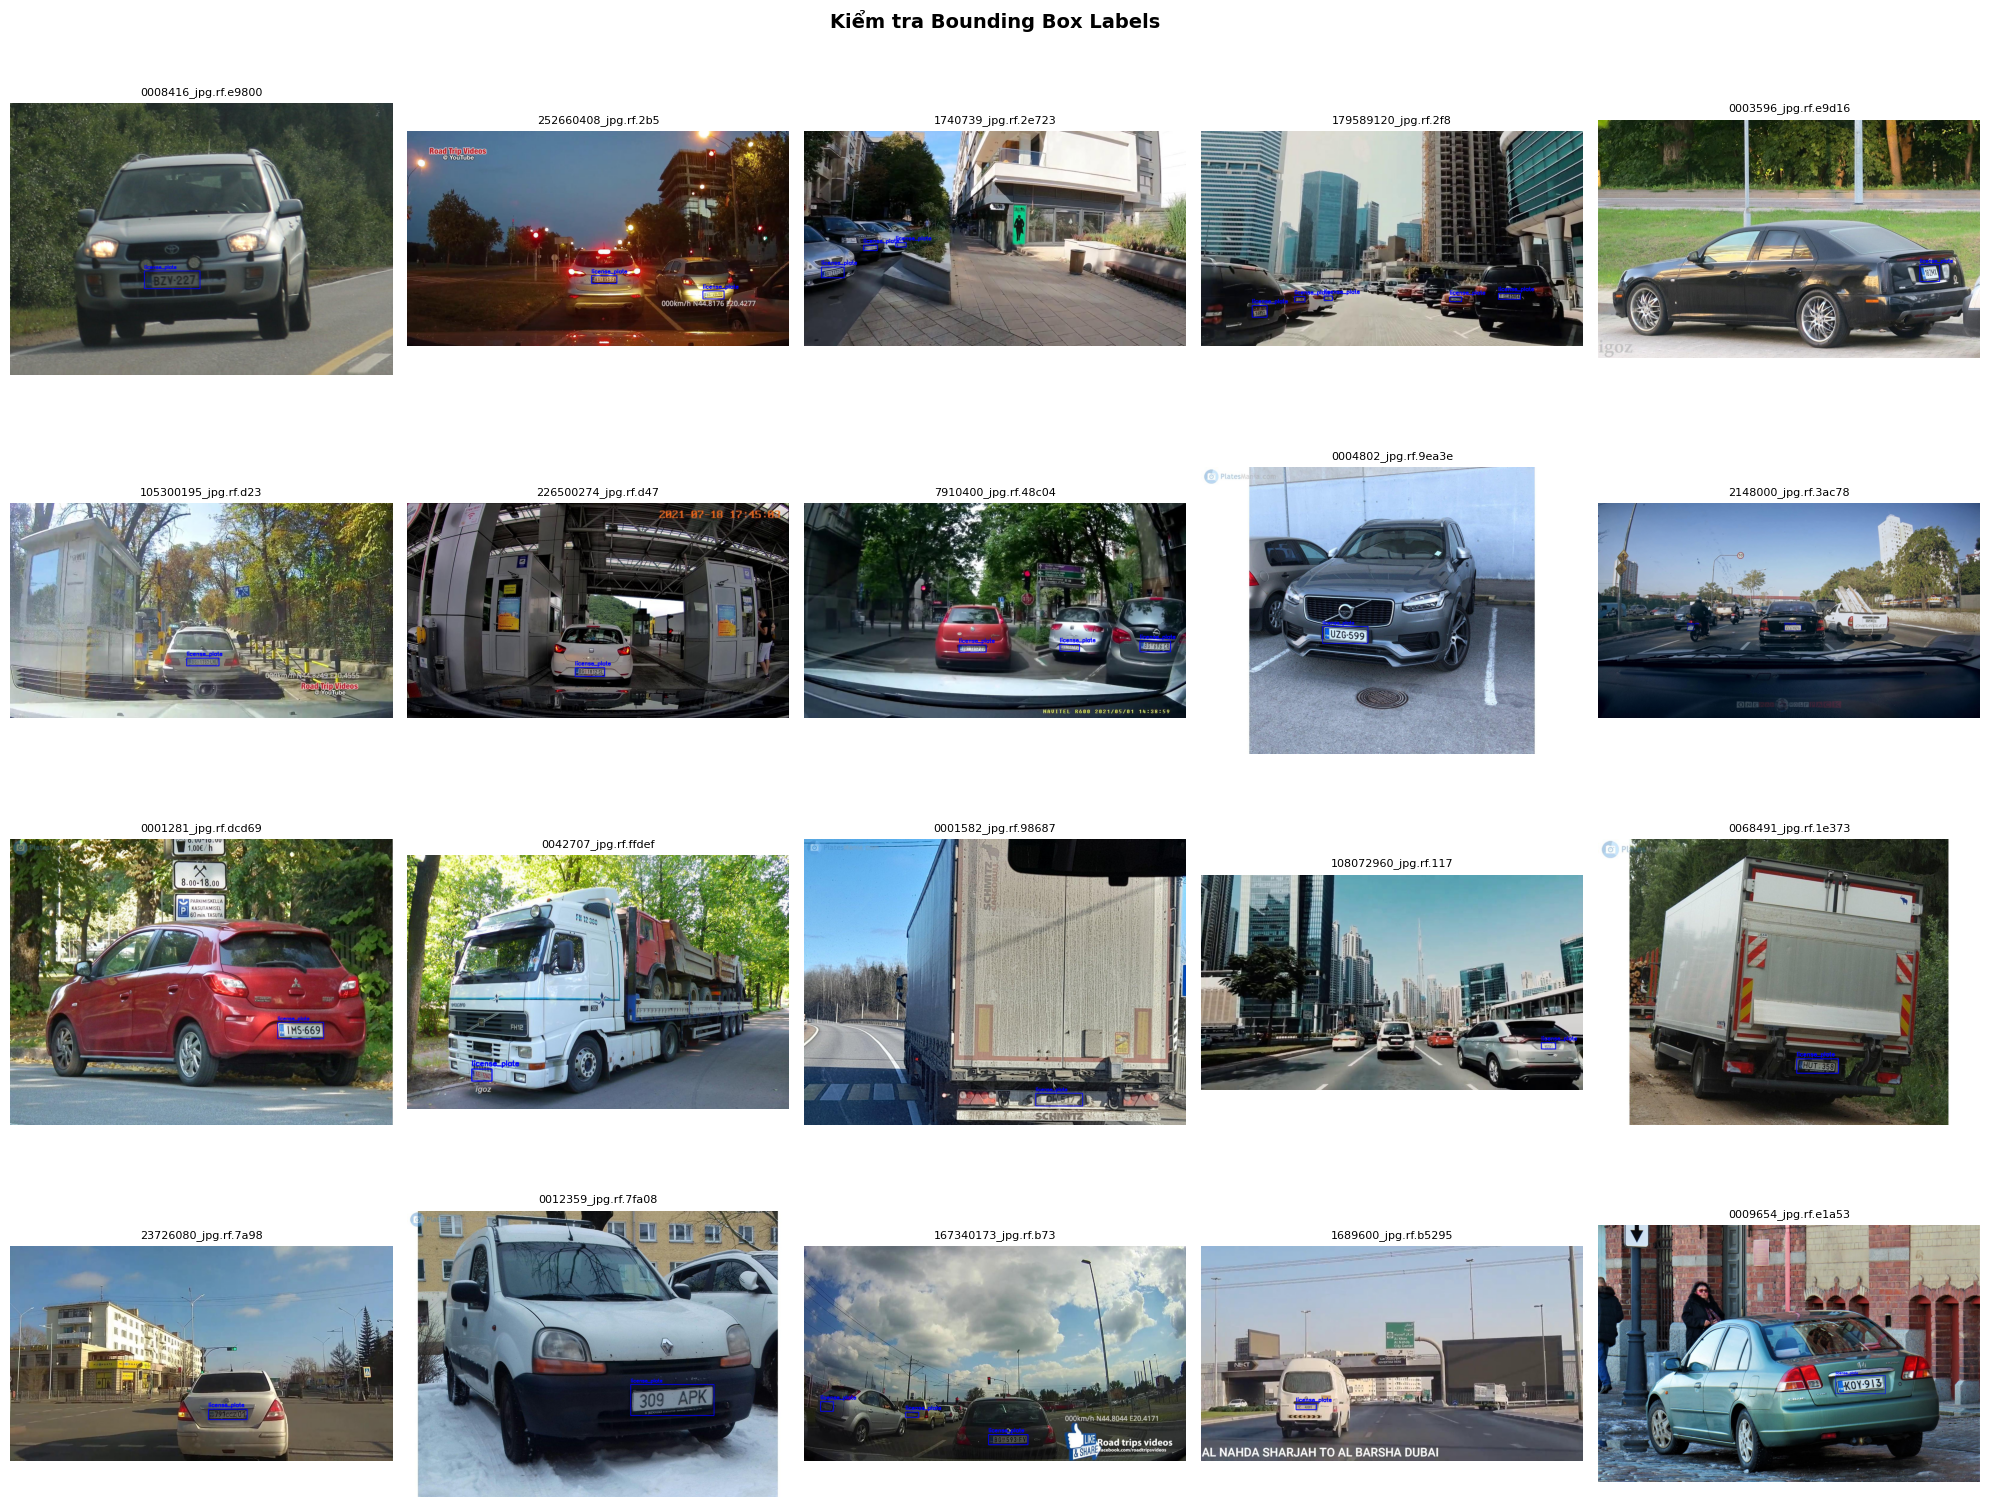

Đã lưu ảnh kiểm tra vào bbox_check.png


In [72]:
import cv2
import os
import random
import matplotlib.pyplot as plt
import matplotlib.patches as patches


# Giữ lại đúng classes như lúc convert
classes = ["license_plate"]
colors = {
    "license_plate" : (0, 0, 255)
}

image_folder = "/mnt/data/license_plate_data/licence-plate-guntur-1/train/images"
label_folder = "/mnt/data/license_plate_data/licence-plate-guntur-1/train/labels"

# Lấy danh sách ảnh có file label tương ứng
valid_pairs = []
for img_file in os.listdir(image_folder):
    if not img_file.endswith((".jpg", ".jpeg", ".png")):
        continue
    stem = os.path.splitext(img_file)[0]
    txt_path = os.path.join(label_folder, stem + ".txt")
    if os.path.exists(txt_path):
        valid_pairs.append((img_file, txt_path))

# Random 20 ảnh
samples = random.sample(valid_pairs, min(20, len(valid_pairs)))

# Vẽ và hiển thị
fig, axes = plt.subplots(4, 5, figsize=(20, 16))
axes = axes.flatten()

for idx, (img_file, txt_path) in enumerate(samples):
    img_path = os.path.join(image_folder, img_file)
    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]

    with open(txt_path) as f:
        for line in f:
            parts = line.strip().split()
            if len(parts) != 5:
                continue
            cls_id, x_c, y_c, bw, bh = int(parts[0]), *map(float, parts[1:])

            # Chuyển YOLO → pixsael
            x1 = int((x_c - bw / 2) * w)
            y1 = int((y_c - bh / 2) * h)
            x2 = int((x_c + bw / 2) * w)
            y2 = int((y_c + bh / 2) * h)

            cls_name = classes[cls_id]
            color = colors[cls_name]

            cv2.rectangle(img, (x1, y1), (x2, y2), color, 2)
            cv2.putText(img, cls_name, (x1, y1 - 8),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.6, color, 2)

    axes[idx].imshow(img)
    axes[idx].set_title(img_file[:20], fontsize=8)
    axes[idx].axis("off")

# Tắt các ô thừa nếu < 20 ảnh2
for i in range(len(samples), len(axes)):
    axes[i].axis("off")

plt.suptitle("Kiểm tra Bounding Box Labels", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig("bbox_check.png", dpi=150, bbox_inches="tight")
plt.show()
print("Đã lưu ảnh kiểm tra vào bbox_check.png")

In [89]:
import os
import shutil
from collections import Counter

src_root = "/mnt/data/license_plate_data/confussionagoreduzenli150lik-1"
dst_root = "/mnt/data/license_plate_data/license"

splits = ["train", "test", "valid"]

for split in splits:
    src_images = os.path.join(src_root, split, "images")
    src_labels = os.path.join(src_root, split, "labels")

    if not os.path.exists(src_images):
        print(f"⏭️  Bỏ qua split '{split}' (không tồn tại): {src_images}")
        continue

    dst_images = os.path.join(dst_root, split, "images")
    dst_labels = os.path.join(dst_root, split, "labels")

    os.makedirs(dst_images, exist_ok=True)
    os.makedirs(dst_labels, exist_ok=True)

    count = 0
    skipped = 0

    for img_file in os.listdir(src_images):
        if not img_file.endswith((".jpg", ".jpeg", ".png")):
            continue

        stem = os.path.splitext(img_file)[0]
        txt_path = os.path.join(src_labels, stem + ".txt")

        if not os.path.exists(txt_path):
            skipped += 1
            continue

        shutil.copy(os.path.join(src_images, img_file), os.path.join(dst_images, img_file))
        shutil.copy(txt_path, os.path.join(dst_labels, stem + ".txt"))
        count += 1

    print(f"\n=== Split: {split} ===")
    print(f"✅ Đã gộp: {count} ảnh")
    print(f"⚠️ Bỏ qua: {skipped} ảnh thiếu label")

    # Kiểm tra tỉ lệ class sau khi gộp cho split này
    counter = Counter()
    for f in os.listdir(dst_labels):
        if not f.endswith(".txt"):
            continue
        with open(os.path.join(dst_labels, f)) as fp:
            for line in fp:
                parts = line.strip().split()
                if parts:
                    counter[parts[0]] += 1

    total = sum(counter.values())
    print(f"Phân bố class trong '{split}' sau khi gộp (tổng {total} object):")
    for cls_id, cnt in sorted(counter.items(), key=lambda x: int(x[0])):
        pct = cnt / total * 100 if total else 0
        print(f"  class {cls_id}: {cnt} ({pct:.2f}%)")


=== Split: train ===
✅ Đã gộp: 1186 ảnh
⚠️ Bỏ qua: 0 ảnh thiếu label
Phân bố class trong 'train' sau khi gộp (tổng 26829 object):
  class 0: 26829 (100.00%)
⏭️  Bỏ qua split 'test' (không tồn tại): /mnt/data/license_plate_data/confussionagoreduzenli150lik-1/test/images

=== Split: valid ===
✅ Đã gộp: 297 ảnh
⚠️ Bỏ qua: 0 ảnh thiếu label
Phân bố class trong 'valid' sau khi gộp (tổng 5923 object):
  class 0: 5923 (100.00%)


In [82]:
import os

def is_valid_yolo_line(line):
    """
    Kiểm tra 1 dòng có đúng format YOLO không:
    class_id x_center y_center width height
    - class_id: số nguyên >= 0
    - x_center, y_center, width, height: số thực trong khoảng (0, 1]
    """
    parts = line.strip().split()
    if len(parts) != 5:
        return False
    class_id_str, *coords_str = parts
    if not class_id_str.isdigit():
        return False
    try:
        coords = [float(x) for x in coords_str]
    except ValueError:
        return False
    for v in coords:
        if v <= 0 or v > 1:
            return False
    return True
def clean_invalid_yolo_pairs(images_dir, labels_dir, dry_run=False):
    """
    Xóa cặp file ảnh + label nếu label có dòng sai format YOLO.
    Trả về (kept, removed) để tổng hợp báo cáo.
    """
    removed = 0
    kept = 0
    for label_file in os.listdir(labels_dir):
        if not label_file.endswith(".txt"):
            continue
        label_path = os.path.join(labels_dir, label_file)
        stem = os.path.splitext(label_file)[0]
        with open(label_path, "r") as f:
            lines = [l for l in f.readlines() if l.strip()]
        is_valid_file = all(is_valid_yolo_line(line) for line in lines)
        if not is_valid_file:
            img_path = None
            for ext in (".jpg", ".jpeg", ".png"):
                candidate = os.path.join(images_dir, stem + ext)
                if os.path.exists(candidate):
                    img_path = candidate
                    break
            if dry_run:
                print(f"[SẼ XÓA] {label_file}" + (f" + {os.path.basename(img_path)}" if img_path else " (không thấy ảnh)"))
            else:
                os.remove(label_path)
                if img_path:
                    os.remove(img_path)
                print(f"❌ Đã xóa: {label_file}" + (f" + {os.path.basename(img_path)}" if img_path else " (không thấy ảnh)"))
            removed += 1
        else:
            kept += 1

    return kept, removed
# ==== Chạy trên cả 3 tập train / valid / test ====

root_dir = "/mnt/data/license_plate_data/license"
splits = ["train", "valid", "test"]
dry_run = False  # để True trước để kiểm tra, xong xuôi thì đổi thành False để xóa thật
summary = {}
for split in splits:
    images_dir = os.path.join(root_dir, split, "images")
    labels_dir = os.path.join(root_dir, split, "labels")
    if not os.path.exists(labels_dir):
        print(f"\n⏭️  Bỏ qua split '{split}' (không tồn tại): {labels_dir}")
        continue
    print(f"\n=== Đang xử lý split: {split} ===")
    kept, removed = clean_invalid_yolo_pairs(images_dir, labels_dir, dry_run=dry_run)
    summary[split] = (kept, removed)

print("\n===== TỔNG KẾT =====")
for split, (kept, removed) in summary.items():
    print(f"{split}: giữ {kept} cặp hợp lệ, {'sẽ xóa' if dry_run else 'đã xóa'} {removed} cặp sai format")


=== Đang xử lý split: train ===
❌ Đã xóa: car_00782_jpg.rf.efbb31fb94030311b18dfb73bff5f8c1.txt + car_00782_jpg.rf.efbb31fb94030311b18dfb73bff5f8c1.jpg
❌ Đã xóa: plate-10-_jpg.rf.933faee67d3e5f2774b4dc6232e33d28.txt + plate-10-_jpg.rf.933faee67d3e5f2774b4dc6232e33d28.jpg
❌ Đã xóa: suggested-kXMLhvscKeAjkp42npAS_jpg.rf.5e6410f4c9d31a791acf1a6805206109.txt + suggested-kXMLhvscKeAjkp42npAS_jpg.rf.5e6410f4c9d31a791acf1a6805206109.jpg
❌ Đã xóa: car_00772_jpg.rf.c030c95e10667f2e35abf1c7c86028d2.txt + car_00772_jpg.rf.c030c95e10667f2e35abf1c7c86028d2.jpg
❌ Đã xóa: suggested-5wVfKyATwlLeSX30MYwH_jpg.rf.6cca7025cdf52362438a61af49433c58.txt + suggested-5wVfKyATwlLeSX30MYwH_jpg.rf.6cca7025cdf52362438a61af49433c58.jpg
❌ Đã xóa: suggested-zC291CNQHXKJnu1lBsGp_jpg.rf.319e622ab92e43d33c2fd260457c7733.txt + suggested-zC291CNQHXKJnu1lBsGp_jpg.rf.319e622ab92e43d33c2fd260457c7733.jpg
❌ Đã xóa: car_00796_jpg.rf.066d3691fc2c44fa934625da27d5ebb7.txt + car_00796_jpg.rf.066d3691fc2c44fa934625da27d5ebb7.jpg
❌

In [87]:


from roboflow import Roboflow
rf = Roboflow(api_key="9aFFodaFHOYgoonrnwoO")
project = rf.workspace("thngs-workspace-nowup").project("confussionagoreduzenli150lik-nj35v")
version = project.version(1)
dataset = version.download("yolo26")
                

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to confussionagoreduzenli150lik-1 in yolo26:: 100%|██████████| 2970/2970 [00:01<00:00, 2342.95it/s]


In [88]:
import os

def clear_all_labels(labels_dir):
    """Ghi đè toàn bộ file .txt trong labels_dir thành file rỗng"""
    count = 0
    for label_file in os.listdir(labels_dir):
        if not label_file.endswith(".txt"):
            continue
        label_path = os.path.join(labels_dir, label_file)
        with open(label_path, "w") as f:
            f.write("")  # ghi đè thành rỗng
        count += 1
    return count


# ==== Chạy trên cả 3 tập train / valid / test ====

root_dir = "/mnt/data/license_plate_data/confussionagoreduzenli150lik-1"
splits = ["train", "valid", "test"]

total = 0
for split in splits:
    labels_dir = os.path.join(root_dir, split, "labels")

    if not os.path.exists(labels_dir):
        print(f"⏭️  Bỏ qua split '{split}' (không tồn tại): {labels_dir}")
        continue

    count = clear_all_labels(labels_dir)
    total += count
    print(f"✅ {split}: đã làm rỗng {count} file label")

print(f"\n🎯 Tổng cộng đã làm rỗng {total} file label")

✅ train: đã làm rỗng 1186 file label
✅ valid: đã làm rỗng 297 file label
⏭️  Bỏ qua split 'test' (không tồn tại): /mnt/data/license_plate_data/confussionagoreduzenli150lik-1/test/labels

🎯 Tổng cộng đã làm rỗng 1483 file label


In [94]:
import os

def count_empty_labels(labels_dir):
    """Đếm số file .txt rỗng (không có nội dung) trong labels_dir"""
    empty_count = 0
    total_count = 0

    for label_file in os.listdir(labels_dir):
        if not label_file.endswith(".txt"):
            continue

        total_count += 1
        label_path = os.path.join(labels_dir, label_file)

        if os.path.getsize(label_path) == 0:
            empty_count += 1
        else:
            # Phòng trường hợp file chỉ chứa khoảng trắng/dòng trống
            with open(label_path, "r") as f:
                content = f.read().strip()
            if content == "":
                empty_count += 1

    return empty_count, total_count


# ==== Chạy trên cả 3 tập train / valid / test ====

root_dir = "/mnt/data/license_plate_data/license"
splits = ["train", "valid", "test"]

grand_empty = 0
grand_total = 0

for split in splits:
    labels_dir = os.path.join(root_dir, split, "labels")

    if not os.path.exists(labels_dir):
        print(f"⏭️  Bỏ qua split '{split}' (không tồn tại): {labels_dir}")
        continue

    empty_count, total_count = count_empty_labels(labels_dir)
    grand_empty += empty_count
    grand_total += total_count

    print(f"{split}: {empty_count}/{total_count} file rỗng")

print(f"\n🎯 Tổng cộng: {grand_empty}/{grand_total} file label")

train: 2675/21797 file rỗng
valid: 552/5668 file rỗng
test: 119/1122 file rỗng

🎯 Tổng cộng: 3346/28587 file label


In [130]:
from paddleocr import TextRecognition

model = TextRecognition(
    
    model_name="PP-OCRv6_medium_rec",
    engine="onnxruntime"

)

output = model.predict(
    input="/mnt/data/license_plate_data/image/e200f525-abba-44d3-a290-449fd606314e_128.jpg",
    batch_size=1
)

for res in output:
    res.print()
    res.save_to_json(save_path="/mnt/data/license_plate_data/res.json")

Model files already exist. Using cached files. To redownload, please delete the directory manually: `/home/chatbot/.paddlex/official_models/PP-OCRv6_medium_rec_onnx`.
{'res': {'input_path': '/mnt/data/license_plate_data/image/e200f525-abba-44d3-a290-449fd606314e_128.jpg', 'page_index': None, 'rec_text': '2036.3 758', 'rec_score': 0.5375081300735474}}


In [ ]:
from paddleocr import PaddleOCR

ocr = PaddleOCR(
    text_detection_model_name="PP-OCRv6_small_det",
    text_recognition_model_name="PP-OCRv6_small_rec",
    engine="onnxruntime",
    use_doc_orientation_classify=False,
    use_doc_unwarping=False,
    use_textline_orientation=True,
)
result = ocr.predict("/mnt/data/license_plate_data/image/e200f525-abba-44d3-a290-449fd606314e_640.jpg")
for res in result:
    res.print()
    res.save_to_img("output")
    res.save_to_json("output")
results = ocr.ocr()

Creating model: ('PP-LCNet_x1_0_textline_ori', None, 'onnxruntime')
Model files already exist. Using cached files. To redownload, please delete the directory manually: `/home/chatbot/.paddlex/official_models/PP-LCNet_x1_0_textline_ori_onnx`.
2026-09-16 09:15:37.000436751 [W:onnxruntime:, graph.cc:5337 CleanUnusedInitializersAndNodeArgs] Removing initializer 'p2o.pd_op.full.0.0'. It is not used by any node and should be removed from the model.
Creating model: ('PP-OCRv6_small_det', None, 'onnxruntime')
2026-09-16 09:15:37.000462310 [W:onnxruntime:, graph.cc:5337 CleanUnusedInitializersAndNodeArgs] Removing initializer 'p2o.pd_op.full_int_array.6.0'. It is not used by any node and should be removed from the model.
2026-09-16 09:15:37.000467599 [W:onnxruntime:, graph.cc:5337 CleanUnusedInitializersAndNodeArgs] Removing initializer 'p2o.pd_op.full_int_array.3.0'. It is not used by any node and should be removed from the model.
2026-09-16 09:15:37.000470523 [W:onnxruntime:, graph.cc:5337 Cl

In [3]:
import cv2

img = cv2.imread("/mnt/data/license_plate_data/image/F7OA4.jpg")

for width in [640]:
    h, w = img.shape[:2]
    print(f"Original size: {w}x{h}, resizing to width {width}...")
    new_h = int(h * width / w)

    resized = cv2.resize(img, (width, new_h))

    cv2.imwrite(
        f"/mnt/data/license_plate_data/image/e200f525-abba-44d3-a290-449fd606314e_{width}.jpg",
        resized
    )

Original size: 1600x1200, resizing to width 640...
